# Chapter 2

# Understanding the Dataset

---

## Objective

Before building any machine learning model, we must understand the data.

This notebook explores the dataset, identifies the prediction target, and documents key observations that influence the design of our Retrieval-Augmented Generation (RAG) pipeline.

## Why is Dataset Understanding Important?

Machine Learning is not about algorithms first.

It is about understanding the problem.

A good understanding of the data often contributes more to model performance than trying different algorithms.

Before writing any model, we answer:

- What is one row?
- What is one prediction?
- What information is available?
- What information is unavailable?
- What assumptions are safe?

In [1]:
import pandas as pd
import numpy as np

from pathlib import Path

In [2]:
DATA_DIR = Path("../data/raw")

TRAIN_PATH = DATA_DIR / "train.csv"
TEST_PATH = DATA_DIR / "test.csv"

train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)

In [3]:
print(f"Training Shape : {train.shape}")
print(f"Testing Shape  : {test.shape}")

Training Shape : (2000, 8)
Testing Shape  : (500, 7)


In [4]:
train.head()

,id,prompt,A,B,C,D,E,answer
0,1,Pick the best possible answer: What is Martin ...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
1,2,What is accelerator-based light-ion fusion?,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,A
2,3,Determine the correct option: What is the term...,Blueshifting,Redshifting,Reddening,Whitening,Yellowing,C
3,4,Select the most accurate option: What is Marti...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
4,5,Identify the correct statement: What is the co...,"Simultaneity is relative, meaning that two eve...","Simultaneity is relative, meaning that two eve...","Simultaneity is absolute, meaning that two eve...",Simultaneity is a concept that applies only to...,Simultaneity is a concept that applies only to...,A


In [5]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   id      2000 non-null   int64
 1   prompt  2000 non-null   str  
 2   A       2000 non-null   str  
 3   B       2000 non-null   str  
 4   C       2000 non-null   str  
 5   D       2000 non-null   str  
 6   E       2000 non-null   str  
 7   answer  2000 non-null   str  
dtypes: int64(1), str(7)
memory usage: 125.1 KB


In [6]:
train.describe(include="all")

,id,prompt,A,B,C,D,E,answer
count,2000.000000,2000,2000,2000,2000,2000,2000,2000
unique,NaN,1758,316,328,303,318,320,5
top,NaN,Select the most accurate option: How do the Lu...,An improper rotation is the combination of a r...,An improper rotation is the combination of a r...,An improper rotation is the combination of a r...,An improper rotation is the combination of a r...,An improper rotation is the combination of a r...,B
freq,NaN,4,21,21,21,21,21,490
mean,1000.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,577.494589,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,500.750000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,1000.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,1500.250000,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
train.nunique()

id        2000
prompt    1758
A          316
B          328
C          303
D          318
E          320
answer       5
dtype: int64

In [8]:
train["answer"].value_counts()

answer
B    490
C    459
A    369
D    358
E    324
Name: count, dtype: int64

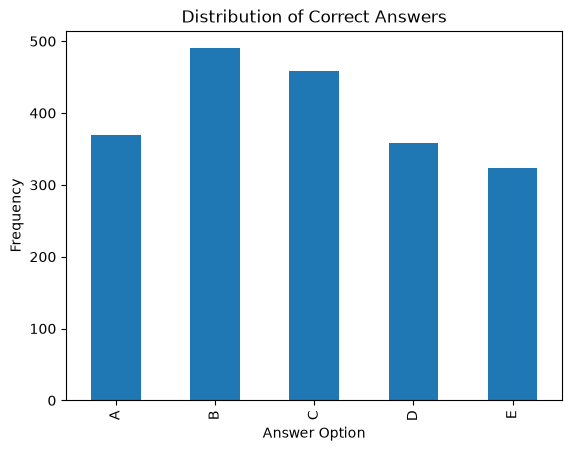

In [9]:
import matplotlib.pyplot as plt

train["answer"].value_counts().sort_index().plot(kind="bar")

plt.title("Distribution of Correct Answers")
plt.xlabel("Answer Option")
plt.ylabel("Frequency")

plt.show()

# Summary

In this notebook we

✓ Loaded the dataset

✓ Understood the structure

✓ Identified the prediction target

✓ Explored data types

✓ Checked missing values

✓ Visualized class distribution

The next notebook will focus on the evaluation metric (MAP@3) before we begin building the Retrieval-Augmented Generation pipeline.